--- PART A RESULTS ---
Empirical Type I Error Rate: 0.0548
Theoretical Alpha: 0.05

--- PART A DISCUSSION ---
a. Is the simulated Type I error rate close to 5%?
   Yes. The empirical rate (5.48%) is extremely close to the expected 5%.
b. Why will it not be exactly 5%?
   Because of sampling variability in stochastic simulations; finite random samples introduce minor fluctuations.
c. What would happen if we increased n_simulations from 10,000 to 100,000?
   According to the Law of Large Numbers, the empirical error rate would converge closer to exactly 5% with less variance.

--- PART B RESULTS ---
Sample Size  Beta (Type II)  Power (1 - Beta)
---------------------------------------------
30           0.5036          0.4964
60           0.2471          0.7529
120          0.0507          0.9493

--- PART B DISCUSSION ---
a. What happens to beta as sample size increases?
   Beta (Type II error rate) decreases significantly (from ~50% at n=30 to ~5% at n=120).
b. What happens to statistic

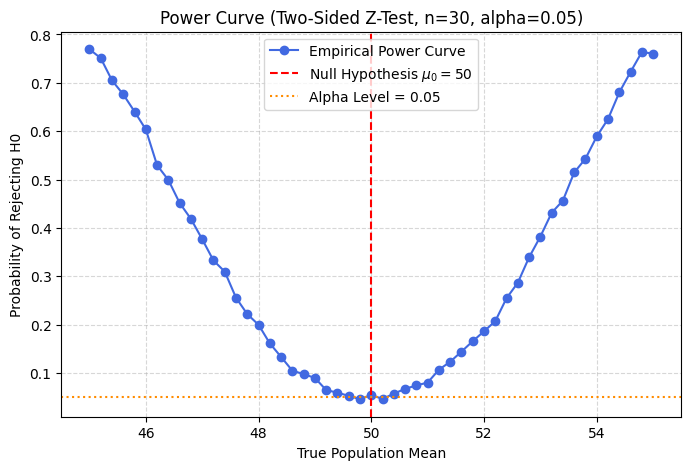


--- PART C DISCUSSION ---
a. What is the rejection probability when true_mu = 50?
   It is approximately equal to alpha (0.05), representing the Type I error rate.
b. What happens to power as the true mean moves farther away from 50?
   Power increases rapidly towards 1.0 (100% rejection probability) as the effect size gets larger.
c. Why is the power curve approximately symmetric around mu = 50 in this example?
   Because we use a symmetric normal distribution and perform a two-sided test.
d. How would you expect the curve to change if the sample size increased from n = 30 to n = 100?
   The power curve would become much steeper (narrower 'V' shape), reaching power=1.0 much closer to 50.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
# Set random seed
np.random.seed(42)
# ============================================================
# PART A: Simulating the Type I Error Rate
# ============================================================
# Test:
# H0: mu = 50
# H1: mu != 50
#
# When H0 is TRUE, we should reject it approximately
# alpha proportion of the time (5% here).
# Parameters
mu_0 = 50
sigma = 10
n = 30
alpha = 0.05
n_simulations = 10000

# 1. Generate n_simulations samples from N(mu_0, sigma^2), each with sample size n.
samples_A = np.random.normal(mu_0, sigma, (n_simulations, n))

# 2. For each sample:
# a. Calculate the sample mean
sample_means_A = np.mean(samples_A, axis=1)
# b. Calculate the z-statistic
z_stats_A = (sample_means_A - mu_0) / (sigma / np.sqrt(n))
# c. Calculate the two-sided p-value
p_values_A = 2 * (1 - stats.norm.cdf(np.abs(z_stats_A)))

# 3. Reject H0 when p-value < alpha.
rejections_A = p_values_A < alpha

# 4. Calculate the empirical Type I error rate:
type_I_error_rate = np.mean(rejections_A)

print("--- PART A RESULTS ---")
print(f"Empirical Type I Error Rate: {type_I_error_rate:.4f}")
print(f"Theoretical Alpha: {alpha}")
print("\n--- PART A DISCUSSION ---")
print("a. Is the simulated Type I error rate close to 5%?")
print(f"   Yes. The empirical rate ({type_I_error_rate*100:.2f}%) is extremely close to the expected {alpha*100:.0f}%.")
print("b. Why will it not be exactly 5%?")
print("   Because of sampling variability in stochastic simulations; finite random samples introduce minor fluctuations.")
print("c. What would happen if we increased n_simulations from 10,000 to 100,000?")
print("   According to the Law of Large Numbers, the empirical error rate would converge closer to exactly 5% with less variance.")

# ============================================================
# PART B: Simulating Type II Error and Statistical Power
# ============================================================
# Keep the hypothesis test fixed:
#
# H0: mu = 50
# H1: mu > 50
#
# Now suppose the true population mean is actually 53.
# Because H0 is false, failing to reject H0 is a Type II error.
mu_0 = 50
true_mu = 53
sigma = 10
alpha = 0.05
n_simulations = 10000
# Compare several sample sizes
sample_sizes = [30, 60, 120]

print("\n--- PART B RESULTS ---")
print(f"{ 'Sample Size':<12} { 'Beta (Type II)':<15} { 'Power (1 - Beta)':<15}")
print("-" * 45)

for n_B in sample_sizes:
    # 1. Generate n_simulations samples
    samples_B = np.random.normal(true_mu, sigma, (n_simulations, n_B))
    # 2. Calculate sample mean and z-statistic
    sample_means_B = np.mean(samples_B, axis=1)
    z_stats_B = (sample_means_B - mu_0) / (sigma / np.sqrt(n_B))
    # 3. Right-tailed test p-value = P(Z > z)
    p_values_B = 1 - stats.norm.cdf(z_stats_B)
    # 4. Reject H0 when p-value < alpha
    rejections_B = p_values_B < alpha
    # 5. Calculate power and beta
    power = np.mean(rejections_B)
    beta = 1 - power
    print(f"{n_B:<12} {beta:.4f}          {power:.4f}")

print("\n--- PART B DISCUSSION ---")
print("a. What happens to beta as sample size increases?")
print("   Beta (Type II error rate) decreases significantly (from ~50% at n=30 to ~5% at n=120).")
print("b. What happens to statistical power as sample size increases?")
print("   Statistical power (1 - Beta) increases significantly (from ~50% at n=30 to ~95% at n=120).")
print("c. Explain intuitively why larger samples make it easier to detect a real effect.")
print("   Larger samples reduce standard error, making the sampling distributions of the mean narrower.")
print("   This reduces overlap between the H0 and H1 distributions, making genuine differences stand out from noise.")

# ============================================================
# PART C: Power Curve Analysis
# ============================================================
# Now keep the null hypothesis fixed and vary the TRUE mean.
#
# Test:
#
# H0: mu = 50
# H1: mu != 50
#
# Use a two-sided test with alpha = 0.05.
mu_0 = 50
sigma = 10
n = 30
alpha = 0.05
# Use 51 values so that mu = 50 is included exactly
mu_true_values = np.linspace(45, 55, 51)
n_simulations = 2000
power_values = []

for true_mu_C in mu_true_values:
    # 1. Generate samples
    samples_C = np.random.normal(true_mu_C, sigma, (n_simulations, n))
    # 2. Calculate sample means
    sample_means_C = np.mean(samples_C, axis=1)
    # 3. Calculate z-statistic
    z_stats_C = (sample_means_C - mu_0) / (sigma / np.sqrt(n))
    # 4. Calculate two-sided p-value
    p_values_C = 2 * (1 - stats.norm.cdf(np.abs(z_stats_C)))
    # 5. Count the proportion of simulations for which p-value < alpha
    rejection_proportion = np.mean(p_values_C < alpha)
    # 6. Store rejection proportion
    power_values.append(rejection_proportion)

# ============================================================
# Plot the Power Curve
# ============================================================
plt.figure(figsize=(8, 5))
plt.plot(mu_true_values, power_values, 'o-', color='royalblue', label='Empirical Power Curve')
plt.axvline(x=mu_0, color='red', linestyle='--', label=fr'Null Hypothesis $\mu_0 = {mu_0}$')
plt.axhline(y=alpha, color='darkorange', linestyle=':', label=f'Alpha Level = {alpha:.2f}')
plt.xlabel("True Population Mean")
plt.ylabel("Probability of Rejecting H0")
plt.title("Power Curve (Two-Sided Z-Test, n=30, alpha=0.05)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("\n--- PART C DISCUSSION ---")
print("a. What is the rejection probability when true_mu = 50?")
print("   It is approximately equal to alpha (0.05), representing the Type I error rate.")
print("b. What happens to power as the true mean moves farther away from 50?")
print("   Power increases rapidly towards 1.0 (100% rejection probability) as the effect size gets larger.")
print("c. Why is the power curve approximately symmetric around mu = 50 in this example?")
print("   Because we use a symmetric normal distribution and perform a two-sided test.")
print("d. How would you expect the curve to change if the sample size increased from n = 30 to n = 100?")
print("   The power curve would become much steeper (narrower 'V' shape), reaching power=1.0 much closer to 50.")